In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("Prêt :", np.__version__)


Prêt : 2.5.4


In [2]:
# Puissance d'emission en dBm
Pe = 43

# Gain antenne station de base en dB
Ge = 15

# Gain antenne telephone en dB
Gr = 0

# Frequence en MHz
f = 1800

# Sensibilite du telephone en dBm
sens = -100


In [3]:
print("Pe =", Pe, "dBm")
print("Ge =", Ge, "dB")
print("Gr =", Gr, "dB")
print("f =", f, "MHz")
print("Sensibilité =", sens, "dBm")


Pe = 43 dBm
Ge = 15 dB
Gr = 0 dB
f = 1800 MHz
Sensibilité = -100 dBm


In [4]:
def affaiblissement_espace_libre(d_km, f_mhz):
    L = 32.44 + 20 * np.log10(d_km) + 20 * np.log10(f_mhz)
    return L

In [5]:
L = affaiblissement_espace_libre(1, 1800)
print("Affaiblissement =", round(L, 2), "dB")

Affaiblissement = 97.55 dB


In [6]:
def puissance_recue(d_km, f_mhz):
    L = affaiblissement_espace_libre(d_km, f_mhz)
    Pr = Pe + Ge + Gr - L
    return Pr
    

In [7]:
print("Puissance reçue =", round(puissance_recue(1, 1800), 2), "dBm")

Puissance reçue = -39.55 dBm


In [8]:
distances_test = [1, 2, 5, 10]

for d in distances_test:
    L = affaiblissement_espace_libre(d, f)
    Pr = puissance_recue(d, f)

    print(f"Distance : {d} km")
    print(f"Affaiblissement : {L:.2f} dB")
    print(f"Puissance reçue : {Pr:.2f} dBm")
    print("---------------------------")

Distance : 1 km
Affaiblissement : 97.55 dB
Puissance reçue : -39.55 dBm
---------------------------
Distance : 2 km
Affaiblissement : 103.57 dB
Puissance reçue : -45.57 dBm
---------------------------
Distance : 5 km
Affaiblissement : 111.52 dB
Puissance reçue : -53.52 dBm
---------------------------
Distance : 10 km
Affaiblissement : 117.55 dB
Puissance reçue : -59.55 dBm
---------------------------


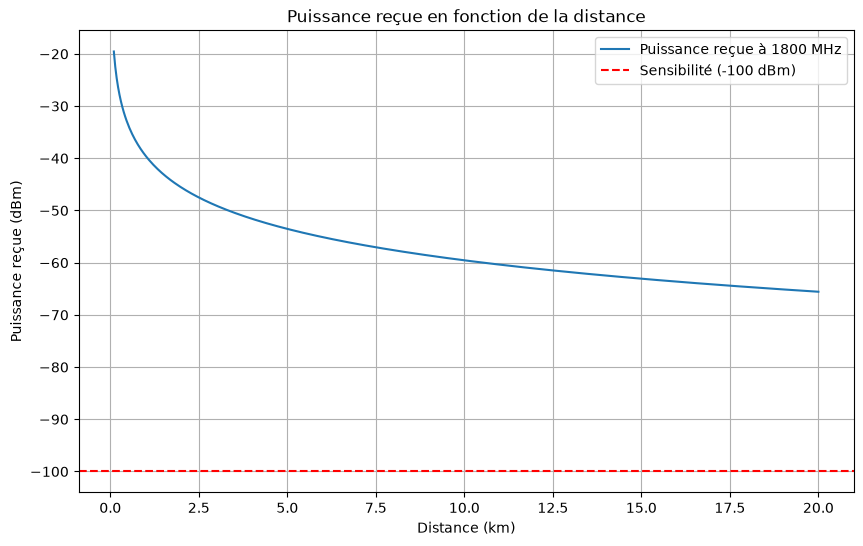

In [9]:
distances = np.linspace(0.1, 20, 500)
puissances = puissance_recue(distances, f)

plt.figure(figsize=(10, 6))
plt.plot(distances, puissances, label="Puissance reçue à 1800 MHz")
plt.axhline(y=sens, color="red", linestyle="--",
            label="Sensibilité (-100 dBm)")

plt.title("Puissance reçue en fonction de la distance")
plt.xlabel("Distance (km)")
plt.ylabel("Puissance reçue (dBm)")
plt.legend()
plt.grid(True)
plt.show()

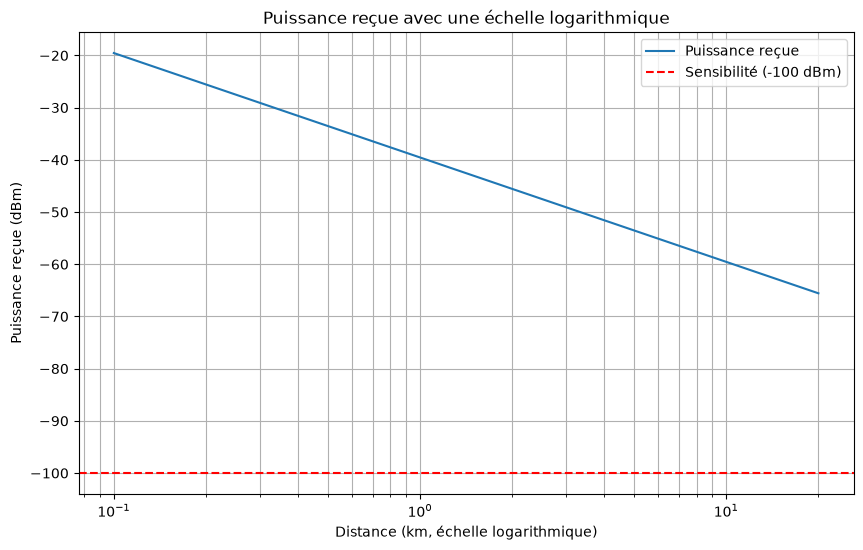

In [10]:
plt.figure(figsize=(10, 6))
plt.plot(distances, puissances, label="Puissance reçue")
plt.axhline(y=sens, color="red", linestyle="--",
            label="Sensibilité (-100 dBm)")

plt.xscale("log")
plt.title("Puissance reçue avec une échelle logarithmique")
plt.xlabel("Distance (km, échelle logarithmique)")
plt.ylabel("Puissance reçue (dBm)")
plt.legend()
plt.grid(True, which="both")
plt.show()

In [11]:
frequences = [700, 900, 1800, 2600, 3500]


700 MHz : puissance à 2 km = -37.36 dBm
900 MHz : puissance à 2 km = -39.55 dBm
1800 MHz : puissance à 2 km = -45.57 dBm
2600 MHz : puissance à 2 km = -48.76 dBm
3500 MHz : puissance à 2 km = -51.34 dBm


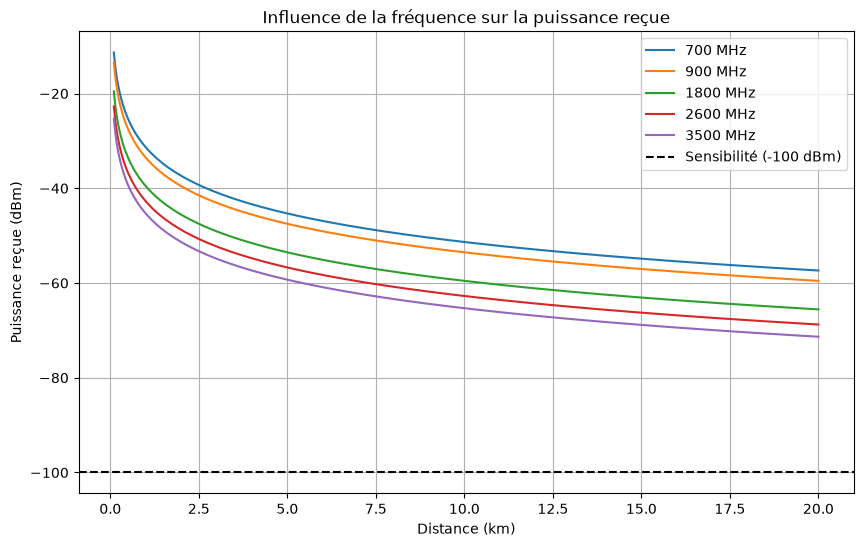

In [12]:
distances = np.linspace(0.1, 20, 500)

plt.figure(figsize=(10, 6))

for freq in frequences:
    puissances_freq = puissance_recue(distances, freq)

    plt.plot(distances, puissances_freq, label=f"{freq} MHz")

    Pr_2km = puissance_recue(2, freq)
    print(f"{freq} MHz : puissance à 2 km = {Pr_2km:.2f} dBm")

plt.axhline(y=sens, color="black", linestyle="--",
            label="Sensibilité (-100 dBm)")

plt.title("Influence de la fréquence sur la puissance reçue")
plt.xlabel("Distance (km)")
plt.ylabel("Puissance reçue (dBm)")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
budget = Pe + Ge + Gr - sens
print("Budget =", budget, "dB")

Budget = 158 dB


In [14]:
def portee(f_mhz, pertes_supp=0):
    budget = Pe + Ge + Gr - sens - pertes_supp

    d_km = 10 ** (
        (budget - 32.44 - 20 * np.log10(f_mhz)) / 20
    )

    return d_km

In [15]:
for freq in frequences:
    d = portee(freq)
    print(f"{freq} MHz : portée = {d:.2f} km")

700 MHz : portée = 2709.58 km
900 MHz : portée = 2107.45 km
1800 MHz : portée = 1053.73 km
2600 MHz : portée = 729.50 km
3500 MHz : portée = 541.92 km


In [16]:
for freq in frequences:
    d = portee(freq, pertes_supp=30)

    print(
        f"{freq} MHz : portée avec 30 dB de pertes = {d:.2f} km"
    )

700 MHz : portée avec 30 dB de pertes = 85.68 km
900 MHz : portée avec 30 dB de pertes = 66.64 km
1800 MHz : portée avec 30 dB de pertes = 33.32 km
2600 MHz : portée avec 30 dB de pertes = 23.07 km
3500 MHz : portée avec 30 dB de pertes = 17.14 km


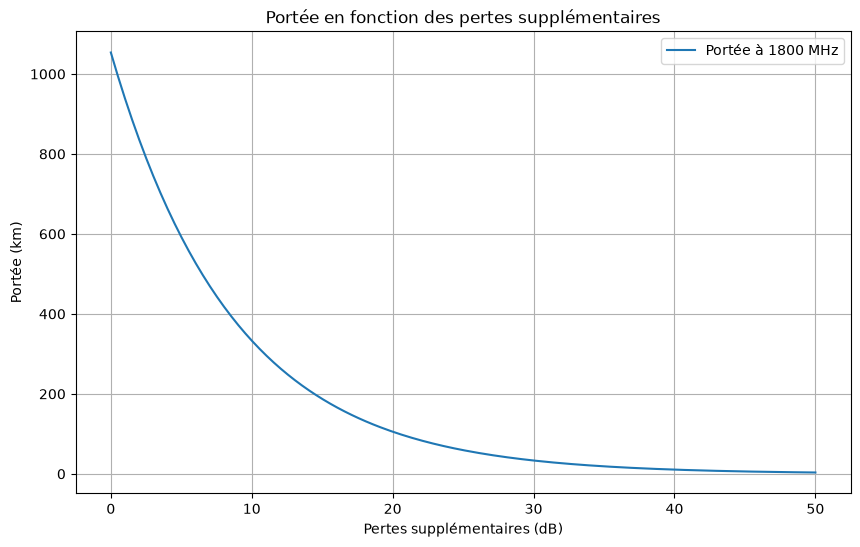

In [17]:
pertes = np.linspace(0, 50, 200)
portees = portee(1800, pertes_supp=pertes)

plt.figure(figsize=(10, 6))
plt.plot(pertes, portees, label="Portée à 1800 MHz")

plt.title("Portée en fonction des pertes supplémentaires")
plt.xlabel("Pertes supplémentaires (dB)")
plt.ylabel("Portée (km)")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
d0 = portee(1800)
d20 = portee(1800, pertes_supp=20)

print(f"Sans pertes supplémentaires : {d0:.2f} km")
print(f"Avec 20 dB de pertes : {d20:.2f} km")
print(f"Facteur de division : {d0 / d20:.2f}")

Sans pertes supplémentaires : 1053.73 km
Avec 20 dB de pertes : 105.37 km
Facteur de division : 10.00
